# `pymu-eval`: Mathematical Expression Parsing for Scalars, NumPy & xarray

**`pymu-eval`** (imported as `pymu_eval`) is a pure-Python implementation of the [muParser](https://github.com/beltoforion/muparser) mathematical expression syntax parser and RPN bytecode evaluator. It brings the full `muParser` syntax—including operator precedence, right-associative exponentiation (`^`), ternary `if-then-else` (`? :`), variadic functions (`sum`, `avg`, `min`, `max`), custom operators, and numerical differentiation—directly to:
- Python scalars (`float`, `int`)
- Multidimensional **NumPy `ndarray`s**
- Labeled **`xarray.DataArray`s** and **`xarray.Dataset`s**

---
### Notebook Contents
1. **Environment Setup (Google Colab & Local)**
2. **Core `muParser` Syntax & Scalar Expressions**
3. **Reusable Bytecode Compilation, Custom Operators & Numerical Differentiation**
4. **Vectorized Computation with NumPy `ndarray`s (1D Signals & 2D Wavelets)**
5. **Earth Observation & Climate Workflows with `xarray.DataArray` and `xarray.Dataset`**
6. **Integer & Bitwise Expression Parsing (`ParserInt`)**
7. **Localization & Structured Error Handling**

## 1. Environment Setup (Google Colab & Local)

Run the cell below to verify dependencies (`numpy`, `xarray`, `matplotlib`) and ensure `pymu_eval` is importable whether you are running locally from the `examples/` directory or inside **Google Colab**.

In [1]:
import os
import sys
from pathlib import Path

# If running from the repository's examples/ folder, add parent directory to sys.path
for candidate in [Path.cwd(), Path.cwd().parent]:
    if (candidate / "pymu_eval").is_dir() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

# In Google Colab, install pymu-eval if needed
if "google.colab" in sys.modules:
    try:
        import pymu_eval  # noqa: F401
    except ImportError:
        print("Tip: Install pymu-eval via '!pip install pymu-eval' or clone the repo and run '!pip install -e .'")

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from pymu_eval import (
    Parser,
    ParserInt,
    ParserError,
    EOprtPrecedence,
    EOprtAssociativity,
    eval_expr,
)

print(f"pymu-eval version : {Parser().GetVersion()}")
print(f"NumPy version     : {np.__version__}")
print(f"xarray version    : {xr.__version__}")

pymu-eval version : 2.3.6 (Development) (20261110; 64BIT; RELEASE; UNICODE)
NumPy version     : 2.5.3
xarray version    : 2026.7.0


## 2. Core `muParser` Syntax & Scalar Expressions

`pymu-eval` supports all standard `muParser` operators and functions:
- **Arithmetic**: `+`, `-`, `*`, `/`, and right-associative power `^` (`2^3^2 == 2^(3^2) == 512`)
- **Comparisons & Logic**: `==`, `!=`, `<`, `<=`, `>`, `>=`, `&&` (AND), `||` (OR)
- **Ternary Conditional**: `condition ? true_expr : false_expr`
- **Built-in Constants**: `_pi` ($\pi$) and `_e` ($e$)
- **Built-in Functions**: `sin`, `cos`, `tan`, `cot`, `asin`, `acos`, `atan`, `atan2`, `sinh`, `cosh`, `tanh`, `coth`, `asinh`, `acosh`, `atanh`, `ln`, `log`, `log2`, `log10`, `exp`, `sqrt`, `abs`, `sign`, `rint`, and variadic `sum`, `avg`, `min`, `max`.

For quick one-off evaluations, use `eval_expr(expr, ...)`:

In [2]:
# Pythagorean trigonometric identity + right-associative power
res1 = eval_expr("sin(theta)^2 + cos(theta)^2 + 2^3^2", theta=0.75)
print("sin(theta)^2 + cos(theta)^2 + 2^3^2 =", res1)

# Variadic functions (sum, avg, min, max)
res2 = eval_expr("avg(10, 20, 30, 40) + max(a, b, c) - min(a, b, c)", a=3.5, b=12.0, c=-1.5)
print("Variadic result                     =", res2)

# Nested ternary operator (? :)
for val in [-4.0, 0.0, 7.5]:
    label_code = eval_expr("x < 0 ? -1 : x == 0 ? 0 : 1", x=val)
    print(f"x = {val:5.1f}  ->  ternary sign = {label_code}")

sin(theta)^2 + cos(theta)^2 + 2^3^2 = 513.0
Variadic result                     = 38.5
x =  -4.0  ->  ternary sign = -1.0
x =   0.0  ->  ternary sign = 0.0
x =   7.5  ->  ternary sign = 1.0


## 3. Reusable Bytecode Compilation, Custom Operators & Numerical Differentiation

When evaluating an expression repeatedly, instantiate `Parser`. The first call to `eval()` compiles the expression into Reverse Polish Notation (RPN) bytecode and folds constant sub-expressions. Subsequent evaluations reuse the bytecode directly.

Both Pythonic `snake_case` (`define_var`, `set_expr`, `eval`) and C++ `CamelCase` (`DefineVar`, `SetExpr`, `Eval`) are supported.

In [3]:
p = Parser()

# Define mutable variable references and a constant
x_var = p.define_var("x", 2.0)
y_var = p.define_var("y", 3.0)
p.define_const("k_spring", 15.0)

# Define a custom 3-argument function
p.define_fun("norm3", lambda u, v, w: (u**2 + v**2 + w**2) ** 0.5)

# Define a custom postfix operator ('d' converts degrees to radians)
p.define_postfix_oprt("d", lambda deg: deg * np.pi / 180.0)

# Define a custom binary operator ('#' for harmonic mean)
p.define_oprt(
    "#",
    lambda a, b: 2.0 * a * b / (a + b),
    prec=EOprtPrecedence.prMUL_DIV,
    associativity=EOprtAssociativity.oaLEFT,
)

p.set_expr("0.5 * k_spring * norm3(x, y, 6)^2 + sin(90d) + (3 # 6)")
print("First evaluation (x=2, y=3) :", p.eval())

# Update x_var in place — no re-parsing needed!
x_var.value = 6.0
print("Updated evaluation (x=6, y=3):", p.eval())

First evaluation (x=2, y=3) : 372.5
Updated evaluation (x=6, y=3): 612.5


### 5-Point 4th-Order Numerical Differentiation (`diff` / `Diff`)

`Parser.diff(var)` computes the 4th-order finite-difference derivative with respect to any variable (scalar, `np.ndarray`, or `xr.DataArray`):

Max absolute error against analytical derivative: 2.70e-09


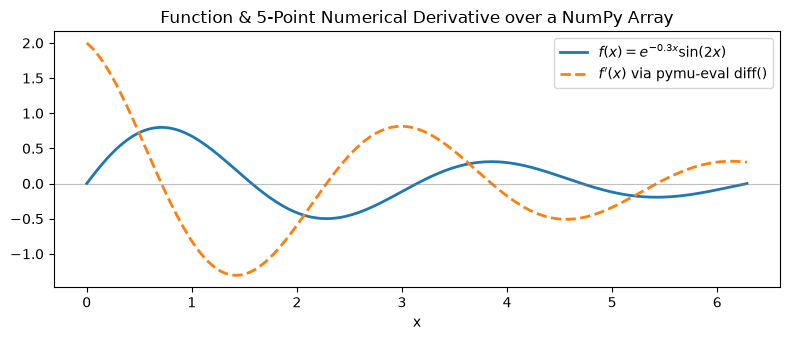

In [4]:
p_diff = Parser("exp(-0.3 * x) * sin(2 * x)")
x_grid = np.linspace(0.0, 2.0 * np.pi, 200)
p_diff.define_var("x", x_grid)

f_val = p_diff.eval()
df_dx_num = p_diff.diff("x")
df_dx_exact = np.exp(-0.3 * x_grid) * (-0.3 * np.sin(2 * x_grid) + 2.0 * np.cos(2 * x_grid))

print(f"Max absolute error against analytical derivative: {np.max(np.abs(df_dx_num - df_dx_exact)):.2e}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(x_grid, f_val, label="$f(x) = e^{-0.3x}\\sin(2x)$", lw=2)
ax.plot(x_grid, df_dx_num, "--", label="$f'(x)$ via pymu-eval diff()", lw=2)
ax.axhline(0, color="gray", lw=0.8, alpha=0.5)
ax.set_xlabel("x")
ax.set_title("Function & 5-Point Numerical Derivative over a NumPy Array")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Vectorized Computation with NumPy `ndarray`s

`pymu-eval` automatically vectorizes operations across 1D, 2D, and 3D NumPy arrays, including element-wise ternary conditionals (`? :`) and NumPy broadcasting.

Below we compute a 2D radially symmetric **Ricker (Mexican Hat) Wavelet** and apply a piecewise threshold mask using a single `muParser` expression:

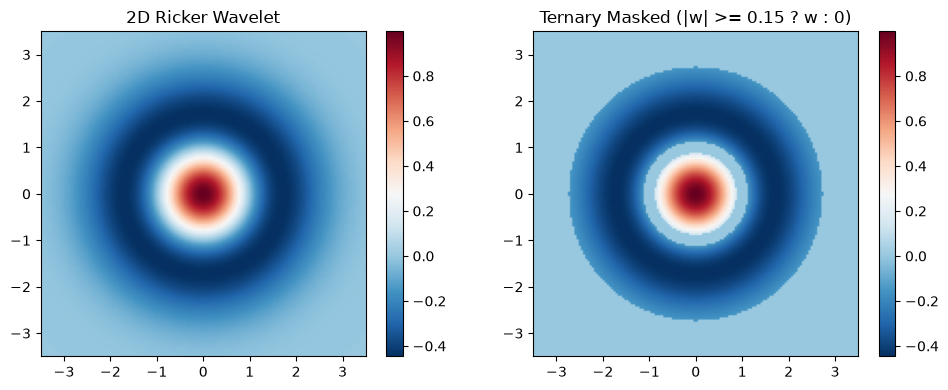

In [5]:
# Create 2D broadcastable coordinate vectors: x is (1, 150), y is (150, 1)
x_1d = np.linspace(-3.5, 3.5, 150)[np.newaxis, :]
y_1d = np.linspace(-3.5, 3.5, 150)[:, np.newaxis]

# Continuous 2D Ricker wavelet
wavelet = eval_expr("(1 - (x^2 + y^2)) * exp(-(x^2 + y^2) / 2)", x=x_1d, y=y_1d)

# Element-wise ternary soft-thresholding: zero out magnitudes < 0.15
wavelet_thresh = eval_expr("abs(w) >= 0.15 ? w : 0.0", w=wavelet)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].imshow(wavelet, extent=[-3.5, 3.5, -3.5, 3.5], cmap="RdBu_r")
axes[0].set_title("2D Ricker Wavelet")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(wavelet_thresh, extent=[-3.5, 3.5, -3.5, 3.5], cmap="RdBu_r")
axes[1].set_title("Ternary Masked (|w| >= 0.15 ? w : 0)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

## 5. Earth Observation & Climate Workflows with `xarray.DataArray` and `xarray.Dataset`

One of the primary use cases for `pymu-eval` is evaluating user-defined band math and physical formulas directly on **`xarray.Dataset`** objects while preserving dimension names (`time`, `lat`, `lon`) and coordinate labels.

When you pass an `xarray.Dataset` to `eval_expr(expr, ds)` or `parser.define_dataset(ds)`, all **data variables** and **coordinates** in `ds` are automatically bound as variables in the expression.

In [6]:
# Construct a synthetic multi-spectral satellite + meteorology xarray.Dataset
rng = np.random.default_rng(7)
lats = np.linspace(51.0, 52.0, 60)
lons = np.linspace(-1.5, 0.0, 80)
lon_grid, lat_grid = np.meshgrid(lons, lats)

# Synthetic reflectance patterns with spatial structure
nir = 0.45 + 0.20 * np.sin(3 * lon_grid) * np.cos(3 * lat_grid) + rng.normal(0, 0.02, lon_grid.shape)
red = 0.12 - 0.05 * np.sin(3 * lon_grid) * np.cos(3 * lat_grid) + rng.normal(0, 0.01, lon_grid.shape)
blue = 0.06 + rng.normal(0, 0.005, lon_grid.shape)
swir = 0.22 - 0.08 * np.cos(2 * lon_grid) + rng.normal(0, 0.01, lon_grid.shape)

# Circular cloud patch in the center of the scene
cloud = (((lon_grid + 0.75) ** 2 + (lat_grid - 51.5) ** 2) < 0.035).astype(int)

# Surface temperature (C) and relative humidity (%)
temp_c = 22.0 - 4.0 * (lat_grid - 51.0) + 2.0 * np.sin(2 * lon_grid)
rh = 65.0 + 15.0 * np.cos(3 * lon_grid)

ds = xr.Dataset(
    data_vars={
        "blue": (("lat", "lon"), np.clip(blue, 0.01, 1.0)),
        "red":  (("lat", "lon"), np.clip(red, 0.01, 1.0)),
        "nir":  (("lat", "lon"), np.clip(nir, 0.01, 1.0)),
        "swir": (("lat", "lon"), np.clip(swir, 0.01, 1.0)),
        "cloud": (("lat", "lon"), cloud),
        "temp_c": (("lat", "lon"), temp_c),
        "rh": (("lat", "lon"), rh),
    },
    coords={"lat": lats, "lon": lons},
)
ds

<xarray.Dataset> Size: 270kB
Dimensions:  (lat: 60, lon: 80)
Coordinates:
  * lat      (lat) float64 480B 51.0 51.02 51.03 51.05 ... 51.97 51.98 52.0
  * lon      (lon) float64 640B -1.5 -1.481 -1.462 ... -0.03797 -0.01899 0.0
Data variables:
    blue     (lat, lon) float64 38kB 0.05487 0.05563 0.05625 ... 0.05828 0.06613
    red      (lat, lon) float64 38kB 0.1604 0.156 0.1515 ... 0.1363 0.1449
    nir      (lat, lon) float64 38kB 0.3344 0.342 0.3325 ... 0.467 0.4263 0.4779
    swir     (lat, lon) float64 38kB 0.3163 0.3051 0.3001 ... 0.1308 0.121 0.136
    cloud    (lat, lon) int64 38kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    temp_c   (lat, lon) float64 38kB 21.72 21.64 21.57 ... 17.85 17.92 18.0
    rh       (lat, lon) float64 38kB 61.84 61.01 60.19 59.39 ... 79.9 79.98 80.0

### Computing Cloud-Masked Spectral Indices & Land Cover Classification

Now we evaluate three expressions directly on `ds`:
1. **Cloud-masked NDVI**: `cloud == 0 ? (nir - red) / (nir + red) : nan`
2. **Cloud-masked EVI**: `cloud == 0 ? 2.5 * (nir - red) / (nir + 6.0 * red - 7.5 * blue + 1.0) : nan`
3. **Vapor Pressure Deficit (VPD in kPa)** from `temp_c` and `rh` using the Tetens equation.

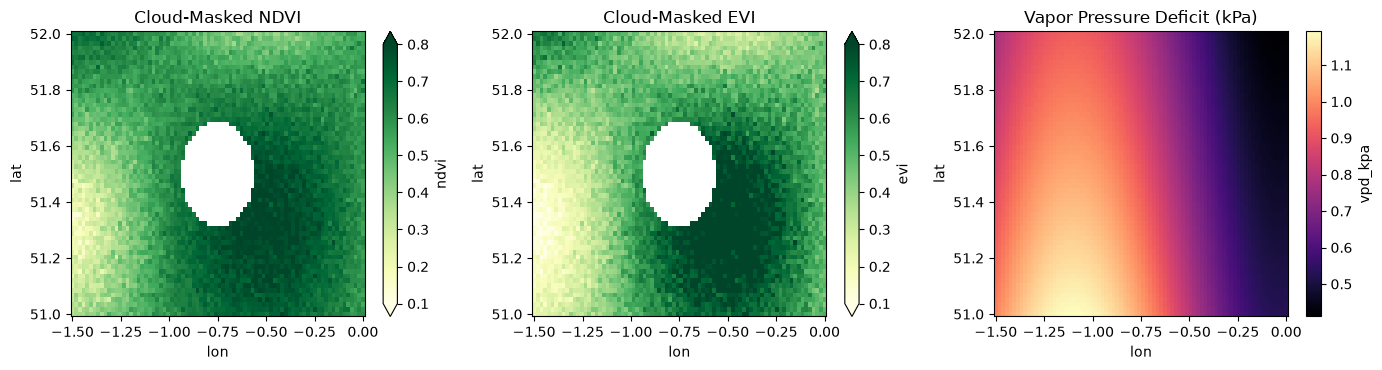

In [7]:
# 1. Cloud-masked NDVI
ds["ndvi"] = eval_expr(
    "cloud == 0 ? (nir - red) / (nir + red) : nan",
    ds,
    nan=np.nan,
)

# 2. Cloud-masked Enhanced Vegetation Index (EVI)
ds["evi"] = eval_expr(
    "cloud == 0 ? 2.5 * (nir - red) / (nir + 6.0 * red - 7.5 * blue + 1.0) : nan",
    ds,
    nan=np.nan,
)

# 3. Vapor Pressure Deficit (kPa) using Tetens saturation vapor pressure formula
ds["vpd_kpa"] = eval_expr(
    "0.61078 * exp((17.27 * temp_c) / (temp_c + 237.3)) * (1.0 - rh / 100.0)",
    ds,
)

# Plot the resulting xarray DataArrays using xarray's built-in plotting
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ds["ndvi"].plot(ax=axes[0], cmap="YlGn", vmin=0.1, vmax=0.8)
axes[0].set_title("Cloud-Masked NDVI")

ds["evi"].plot(ax=axes[1], cmap="YlGn", vmin=0.1, vmax=0.8)
axes[1].set_title("Cloud-Masked EVI")

ds["vpd_kpa"].plot(ax=axes[2], cmap="magma")
axes[2].set_title("Vapor Pressure Deficit (kPa)")

plt.tight_layout()
plt.show()

### Using Dataset Coordinates (`lat`, `lon`) in Expressions

Because `define_dataset` and `eval_expr` bind coordinate arrays as well as data variables, you can reference `lat` and `lon` directly inside expressions (and `xarray` automatically broadcasts 1D coordinates `lat(lat)` and `lon(lon)` into a 2D `(lat, lon)` grid):

In [8]:
# Compute a latitude-weighted NIR index directly referencing the 'lat' coordinate
lat_weighted_nir = eval_expr("nir * cos(lat * _pi / 180.0)", ds)
print("Result type :", type(lat_weighted_nir))
print("Dimensions  :", lat_weighted_nir.dims)
print("Shape       :", lat_weighted_nir.shape)

Result type : <class 'xarray.core.dataarray.DataArray'>
Dimensions  : ('lat', 'lon')
Shape       : (60, 80)


## 6. Integer & Bitwise Expression Parsing (`ParserInt`)

For integer bitmasking (such as QA/QC bitfields in satellite imagery), `ParserInt` supports hexadecimal literals (`0xff`), binary literals (`#1010`), bitwise AND (`&`), bitwise OR (`|`), bit-shifts (`<<`, `>>`), modulo (`%`), and integer division (`/`):

In [9]:
p_int = ParserInt()
qa_flag = p_int.define_var("qa", 0b10110100)

# Extract bit 2 (cloud shadow) and bits 4..5 (confidence level)
p_int.set_expr("(qa & #0100) >> 2")
print("Bit 2 (cloud shadow)    :", int(p_int.eval()))

p_int.set_expr("(qa & 0x30) >> 4")
print("Bits 4..5 (confidence)  :", int(p_int.eval()))

Bit 2 (cloud shadow)    : 1
Bits 4..5 (confidence)  : 3


## 7. Localization & Structured Error Handling

`pymu-eval` supports custom decimal separators, thousands separators, and function argument separators (e.g. European locale using `,` as decimal point and `;` as argument separator), and raises rich `ParserError` exceptions on invalid syntax.

In [10]:
# European locale example: ',' for decimal separator, '.' for thousands, ';' for arguments
p_loc = Parser()
p_loc.set_dec_sep(",")
p_loc.set_thousands_sep(".")
p_loc.set_arg_sep(";")
p_loc.set_expr("sum(1.000,50; 2.500,25; 499,25)")
print("Localized expression 'sum(1.000,50; 2.500,25; 499,25)' =", p_loc.eval())

# Structured error reporting
try:
    eval_expr("2 * (x + sin(y)", x=1.0, y=2.0)
except ParserError as err:
    print("\nCaught ParserError:")
    print("  Error code :", err.code.name)
    print("  Position   :", err.pos)
    print("  Message    :", err.msg)

Localized expression 'sum(1.000,50; 2.500,25; 499,25)' = 4000.0

Caught ParserError:
  Error code : ecMISSING_PARENS
  Position   : 16
  Message    : Missing parenthesis
